In [ ]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

In [ ]:
!pip install -q -U kaggle
!kaggle competitions download -c titanic

100% 34.1k/34.1k [00:00<00:00, 65.2MB/s]



In [ ]:
!kaggle competitions download -c spaceship-titanic
!mkdir -p data
!unzip -o -q spaceship-titanic.zip -d data
!ls data

100% 299k/299k [00:00<00:00, 77.1MB/s]

gender_submission.csv  sample_submission.csv  test.csv	train.csv


In [ ]:
import pandas as pd

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
sample_submission = pd.read_csv("data/sample_submission.csv")

print(train.shape)
print(test.shape)

display(train.head())
train.info()


(8693, 14)
(4277, 13)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


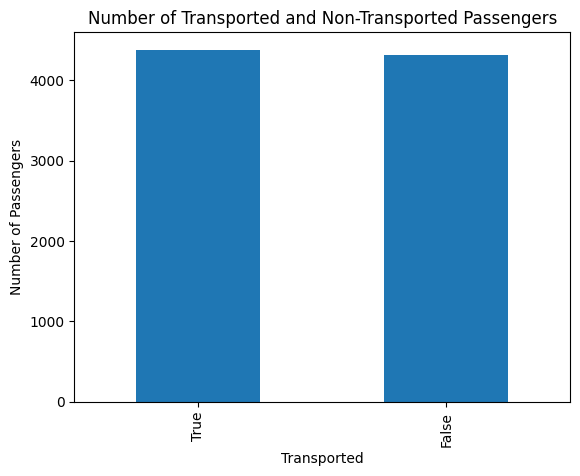

In [ ]:
import matplotlib.pyplot as plt

train["Transported"].value_counts().plot(kind="bar")
plt.title("Number of Transported and Non-Transported Passengers")
plt.xlabel("Transported")
plt.ylabel("Number of Passengers")
plt.show()


In [ ]:
train["Transported"].value_counts()

,count
Transported,
True,4378
False,4315


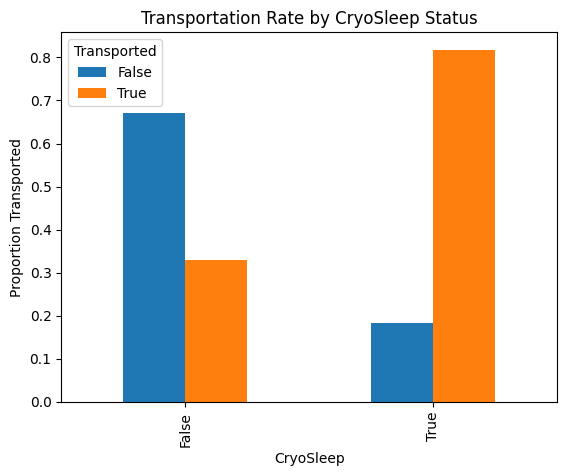

In [ ]:
pd.crosstab(
    train["CryoSleep"],
    train["Transported"],
    normalize="index"
).plot(kind="bar")

plt.title("Transportation Rate by CryoSleep Status")
plt.ylabel("Proportion Transported")
plt.show()


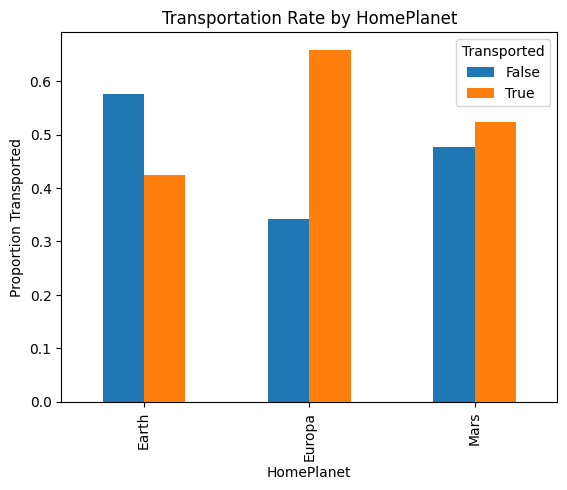

In [ ]:
pd.crosstab(
    train["HomePlanet"],
    train["Transported"],
    normalize="index"
).plot(kind="bar")

plt.title("Transportation Rate by HomePlanet")
plt.ylabel("Proportion Transported")
plt.show()


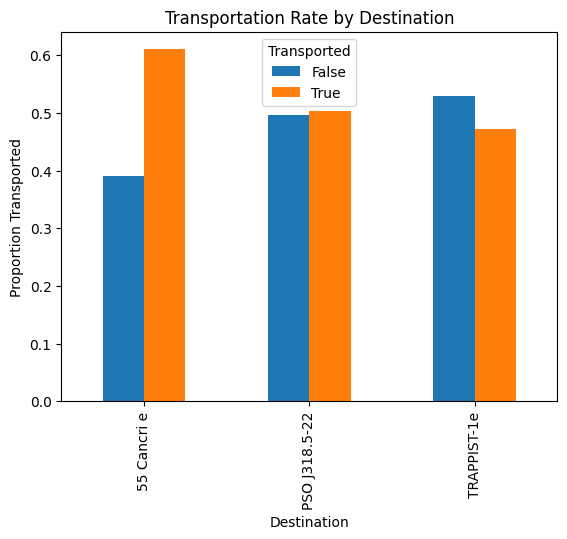

In [ ]:
pd.crosstab(
    train["Destination"],
    train["Transported"],
    normalize="index"
).plot(kind="bar")

plt.title("Transportation Rate by Destination")
plt.ylabel("Proportion Transported")
plt.show()


In [ ]:
missing_values = train.isna().sum().sort_values(ascending=False)
missing_values[missing_values > 0]


,0
CryoSleep,217
ShoppingMall,208
VIP,203
HomePlanet,201
Name,200
Cabin,199
VRDeck,188
Spa,183
FoodCourt,183
Destination,182
